In [1]:
import pandas as pd
from zoneinfo import ZoneInfo
from datetime import datetime as dt
import holidays
import seaborn as sns

In [3]:
df = pd.read_csv('processed_citi_bike_data.csv')

In [ ]:
df.head

,station_id,num_bikes_available,num_docks_available,station_status_last_reported
0,3358,18,7,2018-05-27 19:16:26-04:00
1,3358,1,23,2018-09-05 17:21:25-04:00
2,3358,11,13,2018-03-02 00:09:57-05:00
3,3358,16,7,2018-08-02 03:51:19-04:00
4,3358,3,21,2018-05-13 09:03:33-04:00


In [2]:
stations_df = pd.read_csv('citibike-stations.csv')

In [48]:
stations_df.head()

,capacity,eightd_has_key_dispenser,electric_bike_surcharge_waiver,external_id,has_kiosk,lat,lon,name,region_id,rental_methods,rental_url,short_name,station_id
0,66,True,False,66db5fae-0aca-11e7-82f6-3863bb44ef7c,True,40.764397,-73.973715,Grand Army Plaza & Central Park S,71,"['KEY', 'CREDITCARD']",http://app.citibikenyc.com/S6Lr/IBV092JufD?sta...,6839.1,281
1,33,True,False,66db6da2-0aca-11e7-82f6-3863bb44ef7c,True,40.704633,-74.013617,Broadway & Battery Pl,71,"['KEY', 'CREDITCARD']",http://app.citibikenyc.com/S6Lr/IBV092JufD?sta...,4962.01,304
2,64,False,False,66dbc982-0aca-11e7-82f6-3863bb44ef7c,True,40.755103,-73.974987,E 47 St & Park Ave,71,"['KEY', 'CREDITCARD']",http://app.citibikenyc.com/S6Lr/IBV092JufD?sta...,6584.12,359
3,45,False,False,66dbe441-0aca-11e7-82f6-3863bb44ef7c,True,40.722438,-74.005664,6 Ave & Canal St,71,"['KEY', 'CREDITCARD']",http://app.citibikenyc.com/S6Lr/IBV092JufD?sta...,5500.07,377
4,36,False,False,66dbe601-0aca-11e7-82f6-3863bb44ef7c,True,40.734927,-73.992005,University Pl & E 14 St,71,"['KEY', 'CREDITCARD']",http://app.citibikenyc.com/S6Lr/IBV092JufD?sta...,5905.11,382


In [4]:
stations_df.head()
id_to_shortname = dict(zip(stations_df['station_id'], stations_df['short_name']))
id_to_lat = dict(zip(stations_df['station_id'], stations_df['lat']))
id_to_lon = dict(zip(stations_df['station_id'], stations_df['lon']))
id_to_name = dict(zip(stations_df['station_id'], stations_df['name']))

## Data Processing again bru

In [5]:
df['timestamp'] = pd.to_datetime(df['station_status_last_reported'], format="%Y-%m-%d %H:%M:%S%z", utc=True)
df = df.drop('station_status_last_reported', axis=1)

In [6]:
df.head()

,station_id,num_bikes_available,num_docks_available,timestamp
0,3358,18,7,2018-05-27 23:16:26+00:00
1,3358,1,23,2018-09-05 21:21:25+00:00
2,3358,11,13,2018-03-02 05:09:57+00:00
3,3358,16,7,2018-08-02 07:51:19+00:00
4,3358,3,21,2018-05-13 13:03:33+00:00


In [7]:
df['Month'] = df['timestamp'].dt.month
df['Day'] = df['timestamp'].dt.dayofweek
df['Hour'] = df['timestamp'].dt.hour
df['IsWeekend'] = df['Day'].isin([5,6]).astype(int)



In [8]:
ny_holidays = holidays.US(state='NY')
holiday_date_list = list(ny_holidays.keys())

df['IsHoliday'] = df['timestamp'].dt.date.isin(holiday_date_list).astype(int)

df['IsNonWorkingDay'] = ((df['IsWeekend'] == 1) | (df['IsHoliday'] == 1)).astype(int)

In [14]:
df['shortname'] = df['station_id'].map(id_to_shortname)
df['lat'] = df['station_id'].map(id_to_lat)
df['lon'] = df['station_id'].map(id_to_lon)
df['percentage_available'] = df['num_bikes_available'] / (df['num_bikes_available'] + df['num_docks_available'])

In [ ]:
df = df.sort_values('timestamp').reset_index(drop=True)

### Final Pipeline

In [ ]:
def process_file(csv_file):
    df = pd.read_csv(csv_file)

    df['timestamp'] = pd.to_datetime(df['station_status_last_reported'], format="%Y-%m-%d %H:%M:%S%z", utc=True)
    df = df.drop('station_status_last_reported', axis=1)

    df['Month'] = df['timestamp'].dt.month
    df['Day'] = df['timestamp'].dt.dayofweek
    df['Hour'] = df['timestamp'].dt.hour
    df['IsWeekend'] = df['Day'].isin([5,6]).astype(int)
    df['shortname'] = df['station_id'].map(id_to_shortname)
    df['lat'] = df['station_id'].map(id_to_lat)
    df['lon'] = df['station_id'].map(id_to_lon)
    df['percentage_available'] = df['num_bikes_available'] / (df['num_bikes_available'] + df['num_docks_available'])

    ny_holidays = holidays.US(state='NY')
    holiday_date_list = list(ny_holidays.keys())

    df['IsHoliday'] = df['timestamp'].dt.date.isin(holiday_date_list).astype(int)
    df['IsNonWorkingDay'] = ((df['IsWeekend'] == 1) | (df['IsHoliday'] == 1)).astype(int)

    df = df.sort_values('timestamp').reset_index(drop=True)

    return df
    

<Axes: xlabel='timestamp', ylabel='num_bikes_available'>

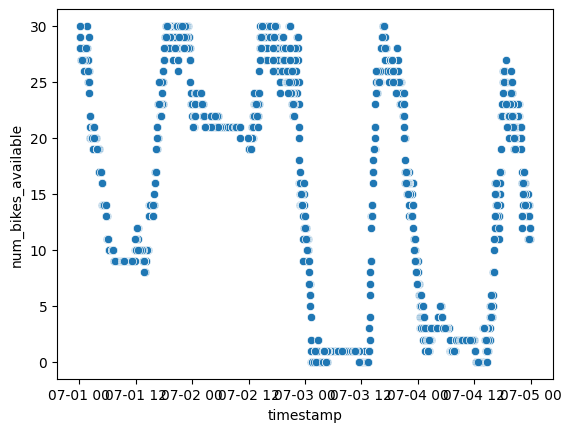

In [70]:
sns.scatterplot(data = df[(df['station_id'] == 303) & (df['timestamp'] < dt(2018, 7, 5, tzinfo = ZoneInfo('UTC'))) & (df['timestamp'] > dt(2018, 7, 1, tzinfo = ZoneInfo('UTC')))], x = 'timestamp', y = 'num_bikes_available')

## Baseline XgBoost

In [15]:
df.head()

,station_id,num_bikes_available,num_docks_available,timestamp,Month,Day,Hour,IsWeekend,IsHoliday,IsNonWorkingDay,shortname,lat,lon,percentage_available
0,3358,18,7,2018-05-27 23:16:26+00:00,5,6,23,1,0,1,3978.13,40.671198,-73.974841,0.720000
1,3358,1,23,2018-09-05 21:21:25+00:00,9,2,21,0,0,0,3978.13,40.671198,-73.974841,0.041667
2,3358,11,13,2018-03-02 05:09:57+00:00,3,4,5,0,0,0,3978.13,40.671198,-73.974841,0.458333
3,3358,16,7,2018-08-02 07:51:19+00:00,8,3,7,0,0,0,3978.13,40.671198,-73.974841,0.695652
4,3358,3,21,2018-05-13 13:03:33+00:00,5,6,13,1,0,1,3978.13,40.671198,-73.974841,0.125000


In [17]:
# Import necessary libraries for time series modeling
import numpy as np
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import xgboost as xgb


In [30]:
feature_columns = ['shortname', 'Month', 'Day', 'Hour', 
                   'IsWeekend', 'IsHoliday', 'IsNonWorkingDay', 'lat', 'lon']

print("Missing values per column:")
print(df[feature_columns].isnull().sum())

df = df[feature_columns + ['percentage_available']].dropna()
print(f"\nData after dropping missing values: {df.shape}")


X = df[feature_columns]
y = df['percentage_available']

Missing values per column:
shortname          113023
Month                   0
Day                     0
Hour                    0
IsWeekend               0
IsHoliday               0
IsNonWorkingDay         0
lat                113023
lon                113023
dtype: int64

Data after dropping missing values: (3227159, 10)


In [ ]:


# Create time series train/validation split
# Use 80% for training, 20% for validation (maintaining temporal order)
split_idx = int(len(df) * 0.8)

X_train = X.iloc[:split_idx]
X_val = X.iloc[split_idx:]
y_train = y.iloc[:split_idx]
y_val = y.iloc[split_idx:]

print(f"Training set size: {len(X_train)} ({len(X_train)/len(df)*100:.1f}%)")
print(f"Validation set size: {len(X_val)} ({len(X_val)/len(df)*100:.1f}%)")

# Get timestamp info - need to map back to original df_sorted indices
# Since df_clean may have dropped some rows, we need to use its index
df_clean_indices = df.index
train_indices = df_clean_indices[:split_idx]
val_indices = df_clean_indices[split_idx:]

print(f"\nTraining date range: {df.loc[train_indices]['timestamp'].min()} to {df.loc[train_indices]['timestamp'].max()}")
print(f"Validation date range: {df.loc[val_indices]['timestamp'].min()} to {df.loc[val_indices]['timestamp'].max()}")

'Lorimer St & Broadway'

In [ ]:
# Prepare features and target
# Select features (excluding target and timestamp)
feature_columns = ['station_id', 'num_docks_available', 'Month', 'Day', 'Hour', 
                   'IsWeekend', 'IsHoliday', 'IsNonWorkingDay', 'lat', 'lon']

# Check for missing values
print("Missing values per column:")
print(df_sorted[feature_columns].isnull().sum())

# Drop rows with missing values if any
df_clean = df_sorted[feature_columns + ['num_bikes_available']].dropna()
print(f"\nData after dropping missing values: {df_clean.shape}")

# Separate features and target
X = df_clean[feature_columns]
y = df_clean['num_bikes_available']

print(f"\nFeatures shape: {X.shape}")
print(f"Target shape: {y.shape}")

In [ ]:
# Train baseline XGBoost model
print("Training baseline XGBoost model...")

# Initialize XGBoost regressor with default parameters
baseline_model = xgb.XGBRegressor(
    objective='reg:squarederror',
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    random_state=42,
    n_jobs=-1
)

# Train the model
baseline_model.fit(X_train, y_train)

# Make predictions
y_train_pred = baseline_model.predict(X_train)
y_val_pred = baseline_model.predict(X_val)

# Calculate metrics
train_mae = mean_absolute_error(y_train, y_train_pred)
train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
train_r2 = r2_score(y_train, y_train_pred)

val_mae = mean_absolute_error(y_val, y_val_pred)
val_rmse = np.sqrt(mean_squared_error(y_val, y_val_pred))
val_r2 = r2_score(y_val, y_val_pred)

print("\n=== Baseline Model Performance ===")
print(f"\nTraining Set:")
print(f"  MAE:  {train_mae:.4f}")
print(f"  RMSE: {train_rmse:.4f}")
print(f"  R²:   {train_r2:.4f}")

print(f"\nValidation Set:")
print(f"  MAE:  {val_mae:.4f}")
print(f"  RMSE: {val_rmse:.4f}")
print(f"  R²:   {val_r2:.4f}")

In [ ]:
# Time Series Cross-Validation
print("Performing Time Series Cross-Validation...")

# Initialize TimeSeriesSplit with 5 folds
tscv = TimeSeriesSplit(n_splits=5)

# Store results for each fold
cv_results = {
    'fold': [],
    'train_mae': [],
    'train_rmse': [],
    'train_r2': [],
    'val_mae': [],
    'val_rmse': [],
    'val_r2': []
}

# Perform cross-validation
for fold_idx, (train_idx, val_idx) in enumerate(tscv.split(X), 1):
    print(f"\nFold {fold_idx}:")
    print(f"  Train size: {len(train_idx)}, Validation size: {len(val_idx)}")
    
    # Split data for this fold
    X_train_fold = X.iloc[train_idx]
    X_val_fold = X.iloc[val_idx]
    y_train_fold = y.iloc[train_idx]
    y_val_fold = y.iloc[val_idx]
    
    # Train model
    model = xgb.XGBRegressor(
        objective='reg:squarederror',
        n_estimators=100,
        max_depth=6,
        learning_rate=0.1,
        random_state=42,
        n_jobs=-1
    )
    model.fit(X_train_fold, y_train_fold)
    
    # Predictions
    y_train_pred_fold = model.predict(X_train_fold)
    y_val_pred_fold = model.predict(X_val_fold)
    
    # Calculate metrics
    train_mae_fold = mean_absolute_error(y_train_fold, y_train_pred_fold)
    train_rmse_fold = np.sqrt(mean_squared_error(y_train_fold, y_train_pred_fold))
    train_r2_fold = r2_score(y_train_fold, y_train_pred_fold)
    
    val_mae_fold = mean_absolute_error(y_val_fold, y_val_pred_fold)
    val_rmse_fold = np.sqrt(mean_squared_error(y_val_fold, y_val_pred_fold))
    val_r2_fold = r2_score(y_val_fold, y_val_pred_fold)
    
    # Store results
    cv_results['fold'].append(fold_idx)
    cv_results['train_mae'].append(train_mae_fold)
    cv_results['train_rmse'].append(train_rmse_fold)
    cv_results['train_r2'].append(train_r2_fold)
    cv_results['val_mae'].append(val_mae_fold)
    cv_results['val_rmse'].append(val_rmse_fold)
    cv_results['val_r2'].append(val_r2_fold)
    
    print(f"  Validation MAE:  {val_mae_fold:.4f}")
    print(f"  Validation RMSE: {val_rmse_fold:.4f}")
    print(f"  Validation R²:   {val_r2_fold:.4f}")

# Calculate average metrics across all folds
print("\n" + "="*50)
print("Cross-Validation Summary")
print("="*50)
print(f"\nAverage Training Metrics:")
print(f"  MAE:  {np.mean(cv_results['train_mae']):.4f} (+/- {np.std(cv_results['train_mae']):.4f})")
print(f"  RMSE: {np.mean(cv_results['train_rmse']):.4f} (+/- {np.std(cv_results['train_rmse']):.4f})")
print(f"  R²:   {np.mean(cv_results['train_r2']):.4f} (+/- {np.std(cv_results['train_r2']):.4f})")

print(f"\nAverage Validation Metrics:")
print(f"  MAE:  {np.mean(cv_results['val_mae']):.4f} (+/- {np.std(cv_results['val_mae']):.4f})")
print(f"  RMSE: {np.mean(cv_results['val_rmse']):.4f} (+/- {np.std(cv_results['val_rmse']):.4f})")
print(f"  R²:   {np.mean(cv_results['val_r2']):.4f} (+/- {np.std(cv_results['val_r2']):.4f})")